# The isogeometric layer: second derivatives, Bezier cells, knot removal, closest point

Four operations act on one patch of a NURBS model, beyond [`iga_refine`, `iga_evaluate` and `iga_sample`](36_iga_refine_evaluate.ipynb): `iga_evaluate(..., derivatives=2)` returns the second derivatives, `iga_bezier_extract` cuts a patch into VTK Bezier cells, `iga_remove_knots` is the inverse of knot insertion (The NURBS Book, A5.8) within a tolerance, and `iga_closest_point` finds the nearest point of a curve or surface. The figures here are plain matplotlib.

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np

import meshioplusplus as mp

s = math.sqrt(0.5)


def arc():
    """The rational quadratic quarter circle of radius 1."""
    return {
        "patches": [
            {
                "degrees": [2],
                "knots": [[0, 0, 0, 1, 1, 1]],
                "control_points": np.array([[1, 0], [1, 1], [0, 1.0]]),
                "weights": np.array([1, s, 1.0]),
            }
        ]
    }


def annulus():
    """The quarter annulus, radii 1 and 2, degrees 2 x 1, a surface in 3-D."""
    pts, w = [], []
    for r in (1.0, 2.0):
        pts += [[r, 0, 0], [r, r, 0], [0, r, 0]]
        w += [1.0, s, 1.0]
    return {
        "patches": [
            {
                "degrees": [2, 1],
                "knots": [[0, 0, 0, 1, 1, 1], [0, 0, 1, 1]],
                "control_points": np.array(pts, dtype=float),
                "weights": np.array(w),
            }
        ]
    }

## Second derivatives

`derivatives=2` adds `second_derivatives` of shape `(N, d, d, space dim)`. On a unit circle the curvature `|x' x x''| / |x'|^3` is 1 everywhere, whatever the parametrisation: the rational arc's second derivatives recover it.

curvature min / max: 0.9999999999999996 1.0000000000000007


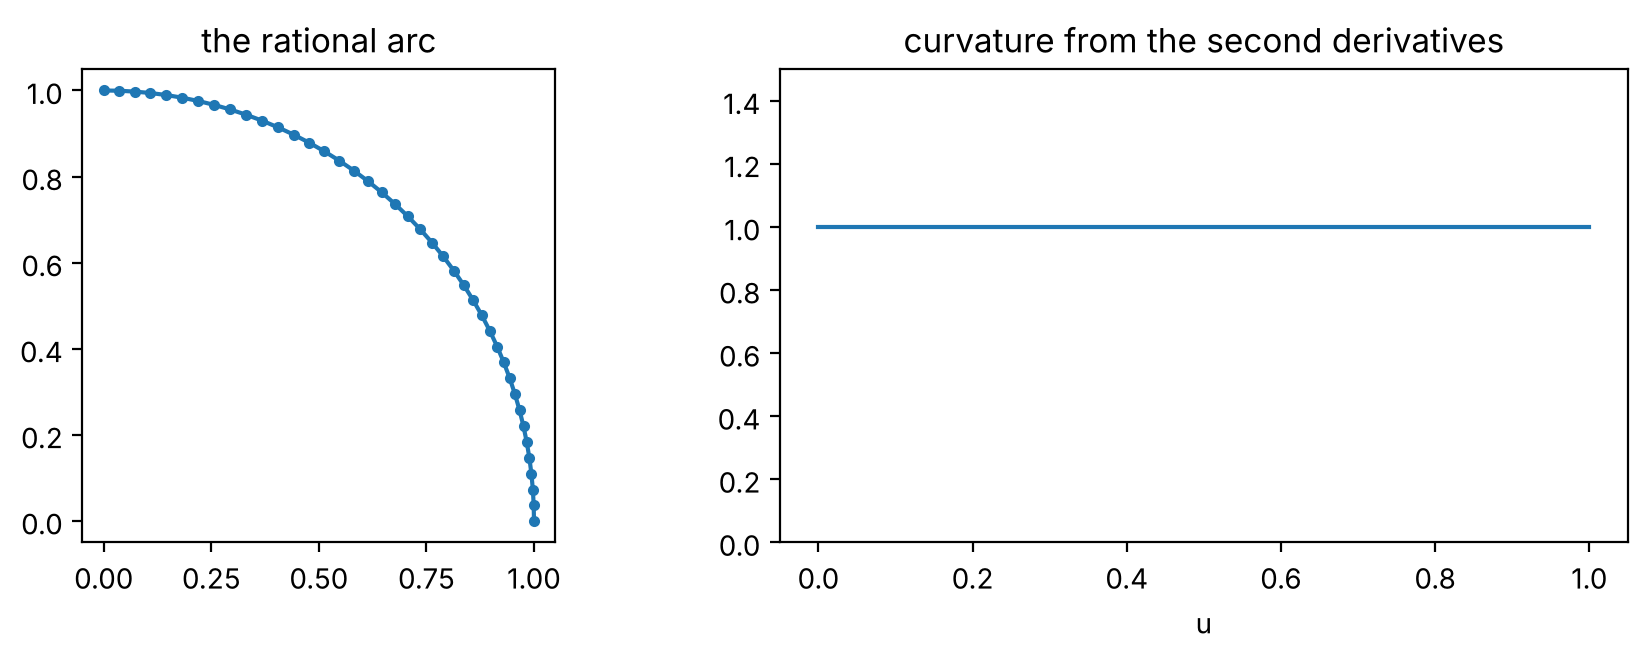

In [2]:
u = np.linspace(0.0, 1.0, 41)[:, None]
ev = mp.iga_evaluate(arc(), u, derivatives=2)
d1 = ev["derivatives"][:, 0, :]
d2 = ev["second_derivatives"][:, 0, 0, :]
curvature = np.abs(d1[:, 0] * d2[:, 1] - d1[:, 1] * d2[:, 0]) / np.linalg.norm(d1, axis=1) ** 3
print("curvature min / max:", curvature.min(), curvature.max())

fig, ax = plt.subplots(1, 2, figsize=(9, 3.4))
ax[0].plot(*ev["points"].T, "-o", ms=3)
ax[0].set_aspect("equal")
ax[0].set_title("the rational arc")
ax[1].plot(u[:, 0], curvature)
ax[1].set_ylim(0, 1.5)
ax[1].set_title("curvature from the second derivatives")
ax[1].set_xlabel("u")
plt.tight_layout()
plt.show()

## Bezier extraction

Every interior knot is raised to multiplicity `p` and the net is cut at its knot spans: one Bezier cell per span product, with `HigherOrderDegrees` and, for a rational patch, `RationalWeights`. The annulus has unequal degrees, so it is elevated first.

refused: meshio++: iga: patch 0 has unequal degrees; Bezier cells take one order, elevate with iga_elevate_degree first
VTK_BEZIER_QUADRILATERAL 6 cells, 54 points
degrees: [2. 2. 0.] weights: [0.837, 0.87, 0.902, 1.0]


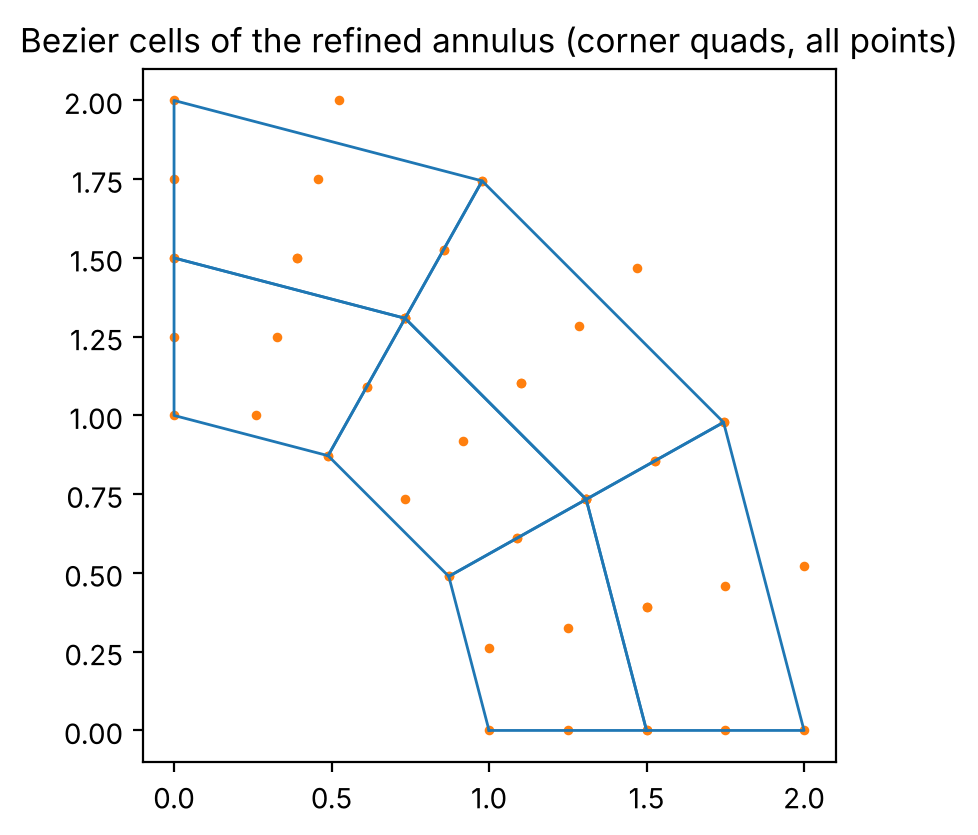

VTU round trip keeps: VTK_BEZIER_QUADRILATERAL ['RationalWeights'] ['HigherOrderDegrees', 'iga:patch', 'iga:span']


In [3]:
model = annulus()
try:
    mp.iga_bezier_extract(model)
except ValueError as exc:
    print("refused:", exc)

refined = mp.iga_refine(model, elevate=(0, 1), subdivisions=(3, 2, 1)).info["nurbs"]
bez = mp.iga_bezier_extract(refined)
print(bez.cells[0].type, len(bez.cells[0].data), "cells,", len(bez.points), "points")
print("degrees:", bez.cell_data["HigherOrderDegrees"][0][0], "weights:", sorted({round(float(w), 3) for w in bez.point_data["RationalWeights"]}))

fig, ax = plt.subplots(figsize=(5, 4.5))
conn = bez.cells[0].data
for cell in conn:
    corners = bez.points[cell[[0, 1, 2, 3, 0]]]  # the first four nodes are the corners
    ax.plot(corners[:, 0], corners[:, 1], "-", color="C0", lw=1)
ax.scatter(bez.points[:, 0], bez.points[:, 1], s=6, color="C1")
ax.set_aspect("equal")
ax.set_title("Bezier cells of the refined annulus (corner quads, all points)")
plt.show()

import tempfile, os

path = os.path.join(tempfile.mkdtemp(), "annulus_bezier.vtu")
mp.write(path, bez)
back = mp.read(path)
print("VTU round trip keeps:", back.cells[0].type, sorted(back.point_data), sorted(back.cell_data))

## Knot removal

Knot insertion adds control points without changing the curve; `iga_remove_knots` takes them out again. With `tolerance=0` it removes only what is exact up to rounding, so refining and then removing restores the original net. A knot the curve really needs stays, until a tolerance allows it to go.

removed: {'knots': [0.25, 0.5, 0.75], 'requested': [1, 1, 1], 'removed': [1, 1, 1], 'num_removed': 3}
control net restored: True


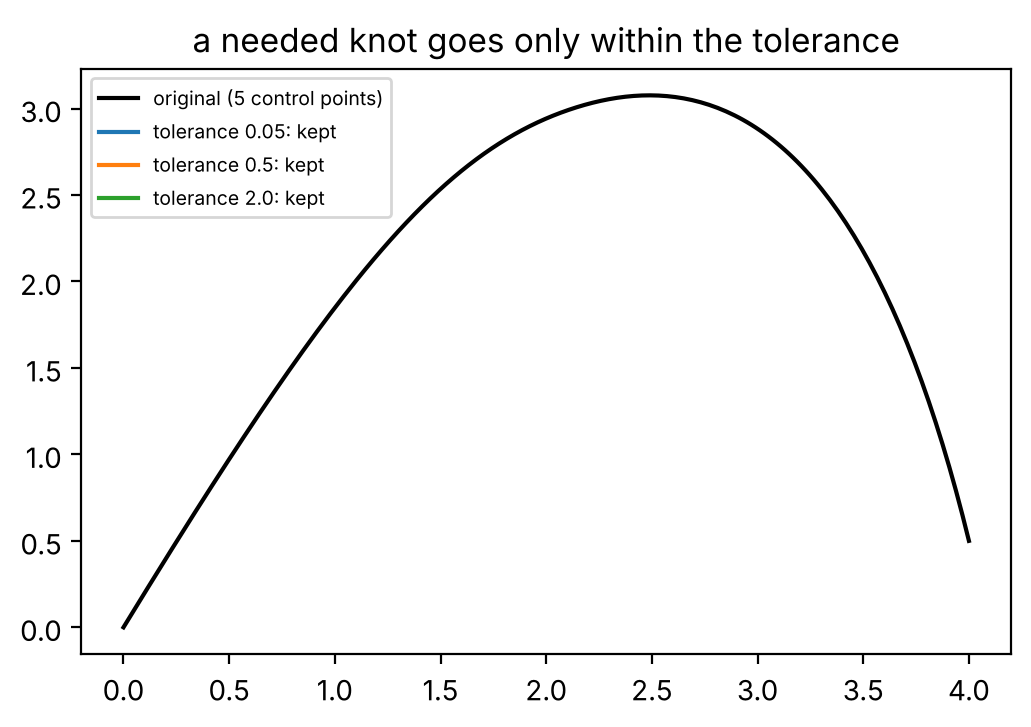

In [4]:
fine = mp.iga_refine(arc(), subdivisions=4)
back, report = mp.iga_remove_knots(fine, return_report=True)
print("removed:", report)
orig = arc()["patches"][0]["control_points"]
got = back.info["nurbs"]["patches"][0]["control_points"]
print("control net restored:", np.abs(got - orig).max() < 1e-12)

curve = {
    "patches": [
        {
            "degrees": [3],
            "knots": [[0, 0, 0, 0, 0.5, 1, 1, 1, 1]],
            "control_points": np.array([[0, 0], [1, 2], [2, 3.5], [3.5, 3], [4, 0.5]]),
            "weights": np.ones(5),
        }
    ]
}
uu = np.linspace(0, 1, 201)[:, None]
ref = mp.iga_evaluate(curve, uu)["points"]
fig, ax = plt.subplots(figsize=(6, 3.8))
ax.plot(*ref.T, "k-", label="original (5 control points)")
for tol, color in ((0.05, "C0"), (0.5, "C1"), (2.0, "C2")):
    out, rep = mp.iga_remove_knots(curve, tolerance=tol, return_report=True)
    if rep["num_removed"]:
        pts = mp.iga_evaluate(out, uu)["points"]
        err = np.abs(pts - ref).max()
        ax.plot(*pts.T, "--", color=color, label=f"tolerance {tol}: knot removed, error {err:.2f}")
    else:
        ax.plot([], [], color=color, label=f"tolerance {tol}: kept")
ax.legend(fontsize=7)
ax.set_title("a needed knot goes only within the tolerance")
plt.show()

## Closest point

A lattice of samples seeds a clamped Newton iteration on the exact second derivatives. A point beyond the patch's edge lands on the edge.

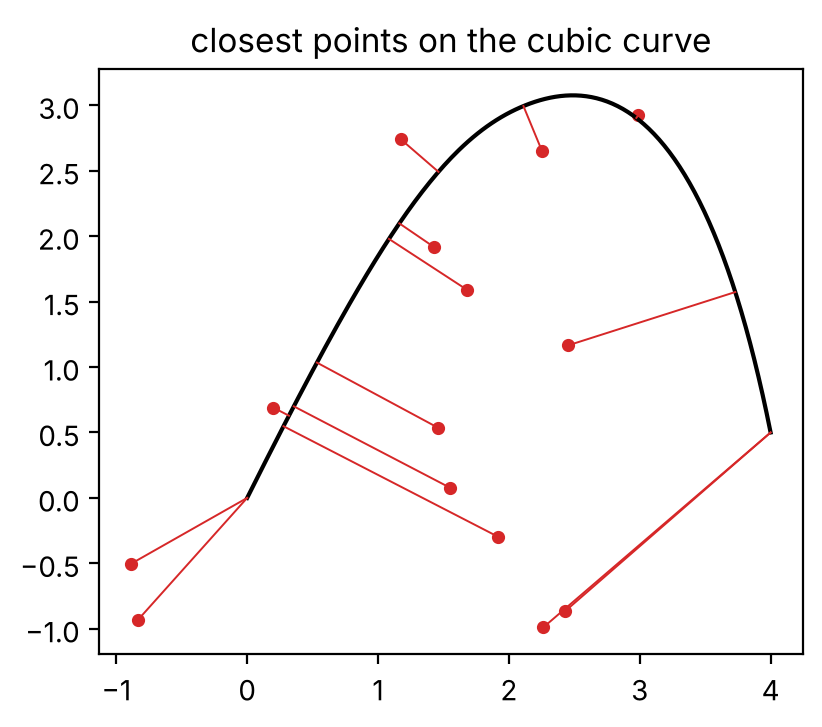

parameters: [[0.4484, 0.5], [0.5, 1.0]]
closest points: [[1.1473, 0.9663, 0.0], [1.4142, 1.4142, 0.0]]
distances: [0.4, 2.2515]


In [5]:
rng = np.random.default_rng(0)
q = rng.uniform(-1.0, 3.0, size=(14, 2))
cp = mp.iga_closest_point(curve, q)
fig, ax = plt.subplots(figsize=(6, 3.8))
ax.plot(*ref.T, "k-")
ax.scatter(*q.T, color="C3", s=14)
for a, b in zip(q, cp["points"]):
    ax.plot(*np.array([a, b]).T, color="C3", lw=0.7)
ax.set_aspect("equal")
ax.set_title("closest points on the cubic curve")
plt.show()

# on a surface in 3-D: a point above the annulus drops straight onto it
pts = np.array([[1.5 * math.cos(0.7), 1.5 * math.sin(0.7), 0.4], [3.0, 3.0, 0.2]])
sc = mp.iga_closest_point(annulus(), pts)
print("parameters:", sc["params"].round(4).tolist())
print("closest points:", sc["points"].round(4).tolist())
print("distances:", sc["distances"].round(4).tolist())